# 🌍 Cross-Lingual Transfer Learning for Bangla WSD

---

## Research Question
> **Can knowledge learned from English WSD (SemEval) transfer to Bangla WSD?**

## Experiments

| Experiment | Train Data | Test Data | Goal |
|---|---|---|---|
| **A — Zero-shot** | English SemEval only | Bangla dataset | Can EN knowledge transfer to BN? |
| **B — Fine-tuned** | English SemEval → then Bangla | Bangla dataset | Does EN pretraining help BN? |
| **C — Bangla only** | Bangla only (baseline) | Bangla dataset | Reference point |

## Previous Results (from main notebook)
| Model | Accuracy | F1 (weighted) |
|---|---|---|
| MFS Baseline | 21.4% | 7.9% |
| mBERT | 65.9% | 60.7% |
| XLM-R | ~0% | ~0% |
| BanglaBERT | **88.1%** | **86.6%** |

## ⚙️ Step 1: Install & Import

In [6]:
# Install dependencies
!pip install transformers datasets nltk openpyxl scikit-learn -q


In [7]:
# ─────────────────────────────────────────────────────────────────
# IMPORTS
# ─────────────────────────────────────────────────────────────────
import os
import re
import json
import random
import warnings
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import matplotlib.pyplot as plt
import matplotlib
matplotlib.rcParams['font.family'] = 'DejaVu Sans'

from torch.utils.data import Dataset, DataLoader
from torch.optim import AdamW
from transformers import (
    AutoTokenizer,
    AutoModel,
    BertModel,
    XLMRobertaModel,
    get_linear_schedule_with_warmup,
)
from sklearn.model_selection import train_test_split
from sklearn.metrics import f1_score, accuracy_score, classification_report
from sklearn.utils.class_weight import compute_class_weight
from collections import Counter, defaultdict

warnings.filterwarnings('ignore')
os.environ['TOKENIZERS_PARALLELISM'] = 'false'

# ── Reproducibility ───────────────────────────────────────────────
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'✅ Device: {DEVICE}')
print(f'✅ PyTorch: {torch.__version__}')
if torch.cuda.is_available():
    print(f'✅ GPU: {torch.cuda.get_device_name(0)}')

✅ Device: cuda
✅ PyTorch: 2.10.0+cu128
✅ GPU: Tesla T4


## ⚙️ Step 2: Configuration

In [8]:
# ─────────────────────────────────────────────────────────────────
# CONFIGURATION
# ─────────────────────────────────────────────────────────────────
class CFG:
    # Paths
    BANGLA_DATA_PATH = '/kaggle/input/datasets/provapaul/dataset-final/dataset_updated.xlsx'
    SEMEVAL_DIR      = '/kaggle/working/semeval_data'
    OUTPUT_DIR       = '/kaggle/working'

    # Model
    MBERT_NAME = 'bert-base-multilingual-cased'
    XLMR_NAME  = 'xlm-roberta-base'

    # Training
    MAX_LEN      = 128
    BATCH_SIZE   = 16
    EPOCHS       = 10
    LEARNING_RATE = 2e-5
    WEIGHT_DECAY  = 0.01
    WARMUP_RATIO  = 0.1
    DROPOUT       = 0.3
    VAL_SPLIT     = 0.15

print('✅ Configuration set!')
print(f'   mBERT  : {CFG.MBERT_NAME}')
print(f'   XLM-R  : {CFG.XLMR_NAME}')
print(f'   MAX_LEN: {CFG.MAX_LEN}')
print(f'   EPOCHS : {CFG.EPOCHS}')

✅ Configuration set!
   mBERT  : bert-base-multilingual-cased
   XLM-R  : xlm-roberta-base
   MAX_LEN: 128
   EPOCHS : 10


In [9]:
# label_counts = df['label'].value_counts()

# print("Min samples per class:", label_counts.min())
# print("Classes with 1 sample :", (label_counts == 1).sum())
# print("Classes with 2 samples :", (label_counts == 2).sum())

## 📂 Step 3: Load Bangla Dataset

In [10]:
# ─────────────────────────────────────────────────────────────────
# LOAD & PREPROCESS BANGLA DATASET
# ─────────────────────────────────────────────────────────────────
df = pd.read_excel(CFG.BANGLA_DATA_PATH)

print(f'✅ Loaded: {df.shape[0]} rows, {df.shape[1]} columns')
print(f'   Columns: {df.columns.tolist()}')
print(f'   Unique words : {df["target_word"].nunique()}')
print(f'   Unique senses: {df.groupby(["target_word","sense_id"]).ngroups}')

# ── Create word_sense label ───────────────────────────────────────
df["word_sense"] = (
    df["target_word"] + "_" +
    df["sense_gloss"].astype(str)
                     .str.replace(" ", "_", regex=False)
                     .str.replace("/", "_", regex=False)
                     .str.replace("(", "", regex=False)
                     .str.replace(")", "", regex=False)
)

# ── Insert [TGT] markers ─────────────────────────────────────────
def insert_tgt(row):
    sentence = str(row['text'])
    word = str(row['target_word'])

    if word in sentence:
        return sentence.replace(word, f'[TGT] {word} [/TGT]', 1)

    return f'[TGT] {word} [/TGT] {sentence}'

df['marked_text'] = df.apply(insert_tgt, axis=1)

# ── Remove duplicate sentence-label pairs ────────────────────────
df = df.drop_duplicates(
    subset=['marked_text', 'word_sense']
).reset_index(drop=True)

# ── Encode labels ────────────────────────────────────────────────
all_senses = sorted(df['word_sense'].unique())

sense2id = {sense: idx for idx, sense in enumerate(all_senses)}
id2sense = {idx: sense for sense, idx in sense2id.items()}

df['label'] = df['word_sense'].map(sense2id)

# ── Remove classes with only 1 sample ────────────────────────────
label_counts = df['label'].value_counts()

rare_labels = label_counts[label_counts < 2].index

print(f"\n⚠ Removing {len(rare_labels)} classes with <2 samples")

df = df[~df['label'].isin(rare_labels)].reset_index(drop=True)

# Recreate labels after filtering
all_senses = sorted(df['word_sense'].unique())

sense2id = {sense: idx for idx, sense in enumerate(all_senses)}
id2sense = {idx: sense for sense, idx in sense2id.items()}

df['label'] = df['word_sense'].map(sense2id)

NUM_BN_CLASSES = len(all_senses)

# ── Word → valid label indices mapping ───────────────────────────
word_to_label_indices = defaultdict(list)

for _, row in (
    df[['target_word', 'word_sense', 'label']]
    .drop_duplicates()
    .iterrows()
):
    word_to_label_indices[row['target_word']].append(row['label'])

# ── Check class distribution ─────────────────────────────────────
label_counts = df['label'].value_counts()

print(f"\n📊 Dataset Statistics")
print(f"   Rows after filtering : {len(df)}")
print(f"   Classes             : {NUM_BN_CLASSES}")
print(f"   Min samples/class   : {label_counts.min()}")
print(f"   Max samples/class   : {label_counts.max()}")

# ── Stratified Train / Validation Split ──────────────────────────
train_df, val_df = train_test_split(
    df,
    test_size=CFG.VAL_SPLIT,
    stratify=df['label'],
    random_state=SEED
)

train_df = train_df.reset_index(drop=True)
val_df = val_df.reset_index(drop=True)

print(f'\n✅ Dataset ready!')
print(f'   Train rows : {len(train_df)}')
print(f'   Val rows   : {len(val_df)}')
print(f'   BN Classes : {NUM_BN_CLASSES}')

✅ Loaded: 7409 rows, 5 columns
   Columns: ['word_id', 'target_word', 'sense_id', 'sense_gloss', 'text']
   Unique words : 181
   Unique senses: 658

⚠ Removing 4 classes with <2 samples

📊 Dataset Statistics
   Rows after filtering : 7404
   Classes             : 660
   Min samples/class   : 2
   Max samples/class   : 30

✅ Dataset ready!
   Train rows : 6293
   Val rows   : 1111
   BN Classes : 660


## 📥 Step 4: Download & Parse SemEval English Data

In [11]:
# ─────────────────────────────────────────────────────────────────
# DOWNLOAD SEMCOR DATA — Robust Multi-Strategy Approach
# Avoids full git clone of the 1GB disambiguate repo
# ─────────────────────────────────────────────────────────────────
import os
import urllib.request
import zipfile
import gzip
import shutil

os.makedirs(CFG.SEMEVAL_DIR, exist_ok=True)

SEMCOR_DATA = f'{CFG.SEMEVAL_DIR}/semcor.data.xml'
SEMCOR_GOLD = f'{CFG.SEMEVAL_DIR}/semcor.gold.key.txt'

def download_file(url, dest, desc=""):
    """Download with progress indicator."""
    print(f'   ⬇️  {desc or url}')
    try:
        urllib.request.urlretrieve(url, dest)
        size = os.path.getsize(dest) / 1024
        print(f'   ✅ Downloaded ({size:.0f} KB)')
        return True
    except Exception as e:
        print(f'   ❌ Failed: {e}')
        return False

# ── Strategy 1: Download UFSAC zip (contains SemCor in WSD format) ──
if not (os.path.exists(SEMCOR_DATA) and os.path.exists(SEMCOR_GOLD)):
    print('📥 Strategy 1: Downloading SemCor from UFSAC/HuggingFace datasets...')
    
    UFSAC_URL = (
        'https://huggingface.co/datasets/UAlberta-NLP/WSD_Evaluation_Framework/'
        'resolve/main/WSD_Evaluation_Framework.zip'
    )
    ZIP_PATH = f'{CFG.SEMEVAL_DIR}/WSD_Framework.zip'
    
    ok = download_file(UFSAC_URL, ZIP_PATH, 'WSD Evaluation Framework (HuggingFace)')
    
    if ok:
        print('   📦 Extracting SemCor files...')
        try:
            with zipfile.ZipFile(ZIP_PATH, 'r') as z:
                # Find SemCor paths inside zip
                semcor_xml_zip  = None
                semcor_gold_zip = None
                for name in z.namelist():
                    if name.endswith('semcor.data.xml'):
                        semcor_xml_zip = name
                    if name.endswith('semcor.gold.key.txt'):
                        semcor_gold_zip = name
                
                if semcor_xml_zip and semcor_gold_zip:
                    with z.open(semcor_xml_zip) as src, open(SEMCOR_DATA, 'wb') as dst:
                        dst.write(src.read())
                    with z.open(semcor_gold_zip) as src, open(SEMCOR_GOLD, 'wb') as dst:
                        dst.write(src.read())
                    print('   ✅ SemCor files extracted from zip!')
                else:
                    print(f'   ⚠️  SemCor not found in zip. Files: {z.namelist()[:10]}')
            os.remove(ZIP_PATH)
        except Exception as e:
            print(f'   ❌ Extraction error: {e}')

# ── Strategy 2: Direct GitHub raw file downloads (sparse) ──────────
if not (os.path.exists(SEMCOR_DATA) and os.path.exists(SEMCOR_GOLD)):
    print('\n📥 Strategy 2: Direct file download from GitHub raw...')
    
    BASE = (
        'https://raw.githubusercontent.com/getalp/disambiguate/master/'
        'data/WSD_Evaluation_Framework/Training_Corpora/SemCor'
    )
    ok_xml  = download_file(f'{BASE}/semcor.data.xml',      SEMCOR_DATA, 'semcor.data.xml')
    ok_gold = download_file(f'{BASE}/semcor.gold.key.txt',  SEMCOR_GOLD, 'semcor.gold.key.txt')
    
    if ok_xml and ok_gold:
        print('   ✅ Direct GitHub download successful!')

# ── Strategy 3: Kaggle dataset input (if user uploaded it) ─────────
if not (os.path.exists(SEMCOR_DATA) and os.path.exists(SEMCOR_GOLD)):
    print('\n📥 Strategy 3: Checking Kaggle input datasets...')
    
    KAGGLE_CANDIDATES = [
        '/kaggle/input/wsd-evaluation-framework/Training_Corpora/SemCor/semcor.data.xml',
        '/kaggle/input/semeval-wsd/semcor.data.xml',
        '/kaggle/input/disambiguate/data/WSD_Evaluation_Framework/Training_Corpora/SemCor/semcor.data.xml',
        '/kaggle/input/wsd-framework/WSD_Evaluation_Framework/Training_Corpora/SemCor/semcor.data.xml',
    ]
    KAGGLE_GOLD = [p.replace('data.xml', 'gold.key.txt') for p in KAGGLE_CANDIDATES]
    
    for xml_p, gold_p in zip(KAGGLE_CANDIDATES, KAGGLE_GOLD):
        if os.path.exists(xml_p) and os.path.exists(gold_p):
            shutil.copy(xml_p,  SEMCOR_DATA)
            shutil.copy(gold_p, SEMCOR_GOLD)
            print(f'   ✅ Found in Kaggle input: {xml_p}')
            break
    else:
        print('   ℹ️  Not found in Kaggle input paths.')

# ── Strategy 4: Minimal synthetic fallback (for pipeline testing) ──
if not (os.path.exists(SEMCOR_DATA) and os.path.exists(SEMCOR_GOLD)):
    print('\n⚠️  All download strategies failed.')
    print('   Creating minimal synthetic SemCor for pipeline testing...')
    print('   (Replace with real SemCor for thesis results)\n')
    
    SYNTHETIC_XML = '''<?xml version="1.0" encoding="UTF-8"?>
<corpus lang="en" source="semcor">
 <text id="d000">
  <sentence id="d000.s000">
   <wf lemma="the" pos="DT">The</wf>
   <instance id="d000.s000.t000" lemma="bank" pos="NOUN">bank</instance>
   <wf lemma="approve" pos="VERB">approved</wf>
   <wf lemma="the" pos="DT">the</wf>
   <instance id="d000.s000.t001" lemma="loan" pos="NOUN">loan</instance>
  </sentence>
  <sentence id="d000.s001">
   <wf lemma="the" pos="DT">The</wf>
   <instance id="d000.s001.t000" lemma="bank" pos="NOUN">bank</instance>
   <wf lemma="of" pos="ADP">of</wf>
   <wf lemma="the" pos="DT">the</wf>
   <instance id="d000.s001.t001" lemma="river" pos="NOUN">river</instance>
   <wf lemma="flood" pos="VERB">flooded</wf>
  </sentence>
  <sentence id="d000.s002">
   <wf lemma="the" pos="DT">The</wf>
   <instance id="d000.s002.t000" lemma="light" pos="NOUN">light</instance>
   <wf lemma="be" pos="VERB">was</wf>
   <wf lemma="bright" pos="ADJ">bright</wf>
   <wf lemma="and" pos="CONJ">and</wf>
   <instance id="d000.s002.t001" lemma="clear" pos="ADJ">clear</instance>
  </sentence>
 </text>
</corpus>'''

    SYNTHETIC_GOLD = (
        'd000.s000.t000 bank%1:14:01::\n'
        'd000.s000.t001 loan%1:21:00::\n'
        'd000.s001.t000 bank%1:17:00::\n'
        'd000.s001.t001 river%1:17:00::\n'
        'd000.s002.t000 light%1:10:00::\n'
        'd000.s002.t001 clear%3:00:02::\n'
    )
    
    with open(SEMCOR_DATA, 'w', encoding='utf-8') as f:
        f.write(SYNTHETIC_XML)
    with open(SEMCOR_GOLD, 'w', encoding='utf-8') as f:
        f.write(SYNTHETIC_GOLD)
    
    print('   ✅ Synthetic SemCor created (6 instances, 3 sentences).')
    print('   ⚠️  IMPORTANT: Upload real SemCor for actual experiments.')
    print()
    print('   📋 To get real SemCor, upload a Kaggle dataset:')
    print('      1. Download from https://ufsac.cs.unistra.fr/data/WSD_Evaluation_Framework.zip')
    print('      2. Extract the /Training_Corpora/SemCor/ folder')
    print('      3. Upload to Kaggle → "New Dataset" → add as input')

# ── Final check ────────────────────────────────────────────────────
print()
if os.path.exists(SEMCOR_DATA) and os.path.exists(SEMCOR_GOLD):
    xml_kb  = os.path.getsize(SEMCOR_DATA) / 1024
    gold_kb = os.path.getsize(SEMCOR_GOLD) / 1024
    mode    = "REAL" if xml_kb > 100 else "SYNTHETIC (test only)"
    print(f'✅ SemCor XML   : {SEMCOR_DATA} ({xml_kb:.0f} KB) [{mode}]')
    print(f'✅ SemCor Gold  : {SEMCOR_GOLD} ({gold_kb:.0f} KB)')
else:
    print('❌ SemCor files still missing — check paths above.')

📥 Strategy 1: Downloading SemCor from UFSAC/HuggingFace datasets...
   ⬇️  WSD Evaluation Framework (HuggingFace)
   ❌ Failed: HTTP Error 401: Unauthorized

📥 Strategy 2: Direct file download from GitHub raw...
   ⬇️  semcor.data.xml
   ❌ Failed: HTTP Error 404: Not Found
   ⬇️  semcor.gold.key.txt
   ❌ Failed: HTTP Error 404: Not Found

📥 Strategy 3: Checking Kaggle input datasets...
   ℹ️  Not found in Kaggle input paths.

⚠️  All download strategies failed.
   Creating minimal synthetic SemCor for pipeline testing...
   (Replace with real SemCor for thesis results)

   ✅ Synthetic SemCor created (6 instances, 3 sentences).
   ⚠️  IMPORTANT: Upload real SemCor for actual experiments.

   📋 To get real SemCor, upload a Kaggle dataset:
      1. Download from https://ufsac.cs.unistra.fr/data/WSD_Evaluation_Framework.zip
      2. Extract the /Training_Corpora/SemCor/ folder
      3. Upload to Kaggle → "New Dataset" → add as input

✅ SemCor XML   : /kaggle/working/semeval_data/semcor.data

In [12]:
!ls /kaggle/working/disambiguate

ls: cannot access '/kaggle/working/disambiguate': No such file or directory


In [13]:
# ─────────────────────────────────────────────────────────────────
# PARSE SEMCOR XML → DataFrame
# Each row = one ambiguous word instance with its sense label
# ─────────────────────────────────────────────────────────────────
import xml.etree.ElementTree as ET

def parse_semcor(xml_path, gold_path, max_samples=None):
    """
    Parse SemCor XML + gold key into a DataFrame.
    Format matches our Bangla dataset structure.
    """
    # Load gold labels: instance_id → sense_key
    gold = {}
    with open(gold_path, 'r', encoding='utf-8') as f:
        for line in f:
            parts = line.strip().split()
            if len(parts) >= 2:
                gold[parts[0]] = parts[1]

    print(f'   Gold labels loaded: {len(gold):,}')

    # Parse XML
    tree = ET.parse(xml_path)
    root = tree.getroot()
    rows = []

    for sentence in root.iter('sentence'):
        tokens    = []
        instances = []

        for elem in sentence:
            text = elem.text if elem.text else ''
            tokens.append(text)
            if elem.tag == 'instance':
                instances.append({
                    'id'        : elem.attrib.get('id', ''),
                    'lemma'     : elem.attrib.get('lemma', text),
                    'pos'       : elem.attrib.get('pos', 'UNK'),
                    'token_idx' : len(tokens) - 1,
                    'surface'   : text,
                })

        sentence_text = ' '.join(t for t in tokens if t)

        for inst in instances:
            if inst['id'] not in gold:
                continue

            sense_key = gold[inst['id']]

            # Insert [TGT] markers — same format as Bangla
            surface  = inst['surface']
            marked   = sentence_text.replace(
                surface,
                f'[TGT] {surface} [/TGT]', 1
            ) if surface else sentence_text

            rows.append({
                'sentence'   : sentence_text,
                'marked_text': marked,
                'target_word': inst['lemma'],
                'surface'    : surface,
                'pos'        : inst['pos'],
                'sense_key'  : sense_key,
                'language'   : 'en',
            })

        if max_samples and len(rows) >= max_samples:
            break

    df_en = pd.DataFrame(rows)
    return df_en


print('📊 Parsing SemCor...')
semcor_df = parse_semcor(SEMCOR_DATA, SEMCOR_GOLD)

# Encode English sense labels
en_senses   = sorted(semcor_df['sense_key'].unique())
en_sense2id = {s: i for i, s in enumerate(en_senses)}
en_id2sense = {i: s for s, i in en_sense2id.items()}
semcor_df['label'] = semcor_df['sense_key'].map(en_sense2id)
NUM_EN_CLASSES = len(en_senses)

# Remove duplicates
semcor_df = semcor_df.drop_duplicates(
    subset=['marked_text','label']
).reset_index(drop=True)

print(f'\n✅ SemCor parsed!')
print(f'   Total instances : {len(semcor_df):,}')
print(f'   Unique words    : {semcor_df["target_word"].nunique():,}')
print(f'   Unique senses   : {NUM_EN_CLASSES:,}')
print(f'   POS distribution:')
print(semcor_df['pos'].value_counts().head(5).to_string())
print()
print(semcor_df[['sentence','target_word','sense_key']].head(3).to_string())

📊 Parsing SemCor...
   Gold labels loaded: 6

✅ SemCor parsed!
   Total instances : 6
   Unique words    : 5
   Unique senses   : 6
   POS distribution:
pos
NOUN    5
ADJ     1

                        sentence target_word       sense_key
0     The bank approved the loan        bank  bank%1:14:01::
1     The bank approved the loan        loan  loan%1:21:00::
2  The bank of the river flooded        bank  bank%1:17:00::


## 🏗️ Step 5: Dataset & Model Classes

In [14]:
# ─────────────────────────────────────────────────────────────────
# PYTORCH DATASET
# Works for both Bangla and English data
# ─────────────────────────────────────────────────────────────────
class WSDDataset(Dataset):
    def __init__(self, dataframe, tokenizer, max_len=CFG.MAX_LEN):
        self.data      = dataframe.reset_index(drop=True)
        self.tokenizer = tokenizer
        self.max_len   = max_len

    def __len__(self):
        return len(self.data)

    def __getitem__(self, idx):
        row      = self.data.iloc[idx]
        encoding = self.tokenizer(
            str(row['marked_text']),
            max_length     = self.max_len,
            padding        = 'max_length',
            truncation     = True,
            return_tensors = 'pt',
        )
        return {
            'input_ids'     : encoding['input_ids'].squeeze(0),
            'attention_mask': encoding['attention_mask'].squeeze(0),
            'labels'        : torch.tensor(row['label'], dtype=torch.long),
        }

print('✅ WSDDataset class defined!')

✅ WSDDataset class defined!


In [15]:
# ─────────────────────────────────────────────────────────────────
# WSD MODEL CLASS
# Generic wrapper — works with mBERT and XLM-R
# ─────────────────────────────────────────────────────────────────
class WSDModel(nn.Module):
    """
    BERT-style model for WSD classification.
    Uses [CLS] token representation → linear classifier.
    Compatible with mBERT and XLM-R.
    """
    def __init__(self, model_name, num_classes, dropout=CFG.DROPOUT):
        super().__init__()
        self.encoder    = AutoModel.from_pretrained(model_name)
        hidden_size     = self.encoder.config.hidden_size
        self.dropout    = nn.Dropout(dropout)
        self.classifier = nn.Linear(hidden_size, num_classes)

    def forward(self, input_ids, attention_mask):
        out = self.encoder(
            input_ids      = input_ids,
            attention_mask = attention_mask,
        )
        cls = out.last_hidden_state[:, 0, :]   # [CLS] token
        return self.classifier(self.dropout(cls))

print('✅ WSDModel class defined!')

✅ WSDModel class defined!


In [16]:
# ─────────────────────────────────────────────────────────────────
# TRAINING & EVALUATION HELPERS
# ─────────────────────────────────────────────────────────────────
def train_one_epoch(model, loader, optimizer, scheduler, criterion, device):
    model.train()
    total_loss = 0.0
    for batch in loader:
        optimizer.zero_grad()
        logits = model(
            batch['input_ids'].to(device),
            batch['attention_mask'].to(device)
        )
        loss = criterion(logits, batch['labels'].to(device))
        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
        optimizer.step()
        scheduler.step()
        total_loss += loss.item()
    return total_loss / len(loader)


def evaluate(model, loader, device):
    model.eval()
    preds, labels = [], []
    with torch.no_grad():
        for batch in loader:
            logits = model(
                batch['input_ids'].to(device),
                batch['attention_mask'].to(device)
            )
            preds.extend(torch.argmax(logits, dim=-1).cpu().numpy())
            labels.extend(batch['labels'].cpu().numpy())
    acc = accuracy_score(labels, preds) * 100
    f1  = f1_score(labels, preds, average='weighted') * 100
    return acc, f1, preds, labels


def build_optimizer_scheduler(model, train_loader, epochs):
    optimizer = AdamW(
        [
            {'params': model.encoder.parameters(),
             'lr': CFG.LEARNING_RATE},
            {'params': model.classifier.parameters(),
             'lr': CFG.LEARNING_RATE * 10},
        ],
        weight_decay=CFG.WEIGHT_DECAY,
    )
    total_steps  = len(train_loader) * epochs
    warmup_steps = int(total_steps * CFG.WARMUP_RATIO)
    scheduler = get_linear_schedule_with_warmup(
        optimizer, warmup_steps, total_steps
    )
    return optimizer, scheduler


def run_training(model, train_loader, val_loader,
                 criterion, epochs, device, exp_name='EXP'):
    optimizer, scheduler = build_optimizer_scheduler(
        model, train_loader, epochs
    )
    best_f1, best_acc = 0.0, 0.0
    history = []

    print(f'\n🚀 {exp_name} — Training for {epochs} epochs')
    print('─' * 60)

    for epoch in range(1, epochs + 1):
        loss      = train_one_epoch(
            model, train_loader, optimizer, scheduler, criterion, device
        )
        acc, f1, _, _ = evaluate(model, val_loader, device)

        is_best = f1 > best_f1
        if is_best:
            best_f1  = f1
            best_acc = acc
            # Save best weights
            torch.save(model.state_dict(),
                       f'{CFG.OUTPUT_DIR}/{exp_name}_best.pt')

        history.append({'epoch': epoch, 'loss': loss, 'acc': acc, 'f1': f1})
        print(f'  Epoch {epoch:02d}/{epochs} | '
              f'Loss: {loss:.4f} | '
              f'Acc: {acc:.2f}% | '
              f'F1: {f1:.2f}%'
              + (' ⭐' if is_best else ''))

    print(f'\n  ✅ Best → Acc: {best_acc:.2f}%  F1: {best_f1:.2f}%')
    return best_acc, best_f1, history


print('✅ Helper functions defined!')

✅ Helper functions defined!


## 🅰️ Step 6: Experiment A — Zero-Shot Transfer
### Train on English SemEval only → Test on Bangla
> Research Question: Can knowledge learned from English WSD transfer to Bangla **without any Bangla training data?**

In [17]:
# ─────────────────────────────────────────────────────────────────
# EXPERIMENT A SETUP
# Train: English SemCor
# Test : Bangla val set (zero-shot)
# Model: mBERT (multilingual — knows both EN and BN)
# ─────────────────────────────────────────────────────────────────
print('=' * 60)
print('  🅰️  EXPERIMENT A: Zero-Shot Transfer')
print('  Train: English SemCor | Test: Bangla (zero-shot)')
print('=' * 60)

mbert_tokenizer = AutoTokenizer.from_pretrained(CFG.MBERT_NAME)

# ── English training data ─────────────────────────────────────────
# Sample to keep training manageable
# Use same size as Bangla train set for fair comparison
en_train_size = min(len(train_df), len(semcor_df))
en_train_df   = semcor_df.sample(n=en_train_size, random_state=SEED)
print(f'\n  English train size : {len(en_train_df):,}')
print(f'  English classes    : {NUM_EN_CLASSES:,}')
print(f'  Bangla val size    : {len(val_df):,}')

# ── DataLoaders ───────────────────────────────────────────────────
en_train_dataset = WSDDataset(en_train_df, mbert_tokenizer)
en_train_loader  = DataLoader(
    en_train_dataset,
    batch_size=CFG.BATCH_SIZE, shuffle=True, num_workers=2
)

# Bangla val — but note: label space is English!
# For zero-shot we test if Bangla words get correct English sense
# We need to create a special zero-shot evaluator
print('\n✅ Experiment A data ready!')

  🅰️  EXPERIMENT A: Zero-Shot Transfer
  Train: English SemCor | Test: Bangla (zero-shot)


config.json:   0%|          | 0.00/625 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/49.0 [00:00<?, ?B/s]

vocab.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]


  English train size : 6
  English classes    : 6
  Bangla val size    : 1,111

✅ Experiment A data ready!


In [18]:
# ─────────────────────────────────────────────────────────────────
# EXPERIMENT A: TRAIN mBERT ON ENGLISH
# ─────────────────────────────────────────────────────────────────

# Model trained on English sense classes
expA_model = WSDModel(
    model_name  = CFG.MBERT_NAME,
    num_classes = NUM_EN_CLASSES,
).to(DEVICE)

# Loss — no class weights for English (too many classes)
expA_criterion = nn.CrossEntropyLoss()

expA_acc, expA_f1, expA_history = run_training(
    model        = expA_model,
    train_loader = en_train_loader,
    val_loader   = en_train_loader,  # validate on English subset
    criterion    = expA_criterion,
    epochs       = CFG.EPOCHS,
    device       = DEVICE,
    exp_name     = 'ExpA_ZeroShot',
)

model.safetensors:   0%|          | 0.00/714M [00:00<?, ?B/s]

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

BertModel LOAD REPORT from: bert-base-multilingual-cased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.



🚀 ExpA_ZeroShot — Training for 10 epochs
────────────────────────────────────────────────────────────
  Epoch 01/10 | Loss: 1.7713 | Acc: 16.67% | F1: 4.76% ⭐
  Epoch 02/10 | Loss: 1.7871 | Acc: 50.00% | F1: 33.33% ⭐
  Epoch 03/10 | Loss: 1.7834 | Acc: 50.00% | F1: 33.33%
  Epoch 04/10 | Loss: 1.4227 | Acc: 50.00% | F1: 33.33%
  Epoch 05/10 | Loss: 1.5272 | Acc: 66.67% | F1: 55.56% ⭐
  Epoch 06/10 | Loss: 1.4844 | Acc: 66.67% | F1: 55.56%
  Epoch 07/10 | Loss: 1.4491 | Acc: 66.67% | F1: 55.56%
  Epoch 08/10 | Loss: 1.4154 | Acc: 66.67% | F1: 55.56%
  Epoch 09/10 | Loss: 1.2687 | Acc: 83.33% | F1: 77.78% ⭐
  Epoch 10/10 | Loss: 1.2434 | Acc: 83.33% | F1: 77.78%

  ✅ Best → Acc: 83.33%  F1: 77.78%


In [19]:
# ─────────────────────────────────────────────────────────────────
# EXPERIMENT A: ZERO-SHOT EVALUATION ON BANGLA
#
# Strategy: Use [CLS] embedding similarity
# 1. Encode each Bangla val sentence → [CLS] embedding
# 2. Encode each Bangla sense label (as text) → embedding
# 3. Find closest sense by cosine similarity
# This is the true zero-shot approach
# ─────────────────────────────────────────────────────────────────
from torch.nn.functional import cosine_similarity

def get_embeddings(model, texts, tokenizer, device, batch_size=32):
    """Get [CLS] embeddings for a list of texts."""
    model.eval()
    all_embeddings = []

    for i in range(0, len(texts), batch_size):
        batch_texts = texts[i:i+batch_size]
        encoded = tokenizer(
            batch_texts,
            max_length=CFG.MAX_LEN, padding='max_length',
            truncation=True, return_tensors='pt'
        )
        with torch.no_grad():
            out = model.encoder(
                input_ids      = encoded['input_ids'].to(device),
                attention_mask = encoded['attention_mask'].to(device),
            )
            embeddings = out.last_hidden_state[:, 0, :]
        all_embeddings.append(embeddings.cpu())

    return torch.cat(all_embeddings, dim=0)


print('📊 Computing zero-shot embeddings...')

# Load best checkpoint
expA_model.load_state_dict(
    torch.load(f'{CFG.OUTPUT_DIR}/ExpA_ZeroShot_best.pt',
               map_location=DEVICE)
)

# Get embeddings for Bangla val sentences
bn_val_texts = val_df['marked_text'].tolist()
bn_val_embs  = get_embeddings(expA_model, bn_val_texts,
                               mbert_tokenizer, DEVICE)
print(f'  Bangla val embeddings : {bn_val_embs.shape}')

# Get embeddings for each Bangla sense (use gloss as text)
bn_sense_texts   = []
bn_sense_labels  = []
for sense_str, label_id in sense2id.items():
    # Use the sense gloss as the sense representation
    gloss = sense_str.replace('_', ' ')
    bn_sense_texts.append(gloss)
    bn_sense_labels.append(label_id)

bn_sense_embs = get_embeddings(expA_model, bn_sense_texts,
                                mbert_tokenizer, DEVICE)
print(f'  Bangla sense embeddings: {bn_sense_embs.shape}')

# Zero-shot prediction: cosine similarity
# For each val sentence, find the closest sense for that word
zeroshot_preds  = []
zeroshot_labels = val_df['label'].tolist()

for i, row in val_df.iterrows():
    word          = row['target_word']
    valid_indices = word_to_label_indices[word]

    # Sentence embedding
    sent_emb = bn_val_embs[val_df.index.get_loc(i)].unsqueeze(0)

    # Sense embeddings for this word only
    sense_emb_indices = [
        bn_sense_labels.index(v)
        for v in valid_indices
        if v in bn_sense_labels
    ]
    if not sense_emb_indices:
        zeroshot_preds.append(valid_indices[0])
        continue

    word_sense_embs = bn_sense_embs[sense_emb_indices]
    sims = cosine_similarity(
        sent_emb.expand(word_sense_embs.shape[0], -1),
        word_sense_embs
    )
    best_idx = sims.argmax().item()
    zeroshot_preds.append(valid_indices[best_idx])

zs_acc = accuracy_score(zeroshot_labels, zeroshot_preds) * 100
zs_f1  = f1_score(zeroshot_labels, zeroshot_preds, average='weighted') * 100

print(f'\n✅ EXPERIMENT A (Zero-Shot) RESULTS:')
print(f'   Accuracy : {zs_acc:.2f}%')
print(f'   F1       : {zs_f1:.2f}%')
print(f'\n   Interpretation:')
if zs_acc > 21.4:
    print(f'   ✅ Better than MFS baseline (21.4%) — transfer signal exists!')
else:
    print(f'   ⚠️  Below MFS baseline — zero-shot transfer is hard for Bangla')
    print(f'      This is still a valid finding for the thesis.')

📊 Computing zero-shot embeddings...
  Bangla val embeddings : torch.Size([1111, 768])
  Bangla sense embeddings: torch.Size([660, 768])

✅ EXPERIMENT A (Zero-Shot) RESULTS:
   Accuracy : 30.96%
   F1       : 19.00%

   Interpretation:
   ✅ Better than MFS baseline (21.4%) — transfer signal exists!


## 🅱️ Step 7: Experiment B — Sequential Fine-tuning
### First train on English → then fine-tune on Bangla
> Research Question: Does English WSD pretraining improve Bangla performance compared to Bangla-only training?

In [20]:
# ─────────────────────────────────────────────────────────────────
# EXPERIMENT B SETUP
# Phase 1: Train mBERT on English SemCor
# Phase 2: Replace classifier head → fine-tune on Bangla
# Test   : Bangla val set
# ─────────────────────────────────────────────────────────────────
print('=' * 60)
print('  🅱️  EXPERIMENT B: Sequential Fine-tuning')
print('  Phase 1: English SemCor')
print('  Phase 2: Fine-tune on Bangla')
print('=' * 60)

# Bangla DataLoaders
bn_train_dataset = WSDDataset(train_df, mbert_tokenizer)
bn_val_dataset   = WSDDataset(val_df,   mbert_tokenizer)

bn_train_loader = DataLoader(
    bn_train_dataset,
    batch_size=CFG.BATCH_SIZE, shuffle=True, num_workers=2
)
bn_val_loader = DataLoader(
    bn_val_dataset,
    batch_size=CFG.BATCH_SIZE * 2, shuffle=False, num_workers=2
)

# Class weights for Bangla
bn_class_weights = compute_class_weight(
    'balanced',
    classes=np.arange(NUM_BN_CLASSES),
    y=train_df['label'].values
)
bn_criterion = nn.CrossEntropyLoss(
    weight=torch.tensor(bn_class_weights, dtype=torch.float32).to(DEVICE)
)

print(f'\n  Bangla train : {len(bn_train_dataset):,}')
print(f'  Bangla val   : {len(bn_val_dataset):,}')
print(f'  BN classes   : {NUM_BN_CLASSES}')
print('\n✅ Experiment B data ready!')

  🅱️  EXPERIMENT B: Sequential Fine-tuning
  Phase 1: English SemCor
  Phase 2: Fine-tune on Bangla

  Bangla train : 6,293
  Bangla val   : 1,111
  BN classes   : 660

✅ Experiment B data ready!


In [21]:
# ─────────────────────────────────────────────────────────────────
# EXPERIMENT B — PHASE 1: Train on English
# ─────────────────────────────────────────────────────────────────
print('📘 Phase 1: Training on English SemCor...')

expB_model = WSDModel(
    model_name  = CFG.MBERT_NAME,
    num_classes = NUM_EN_CLASSES,
).to(DEVICE)

expB_criterion_en = nn.CrossEntropyLoss()

# Train on English
_, _, phase1_history = run_training(
    model        = expB_model,
    train_loader = en_train_loader,
    val_loader   = en_train_loader,
    criterion    = expB_criterion_en,
    epochs       = CFG.EPOCHS,
    device       = DEVICE,
    exp_name     = 'ExpB_Phase1_EN',
)

# Load best Phase 1 weights
expB_model.load_state_dict(
    torch.load(f'{CFG.OUTPUT_DIR}/ExpB_Phase1_EN_best.pt',
               map_location=DEVICE)
)
print('\n✅ Phase 1 complete — English encoder ready!')

📘 Phase 1: Training on English SemCor...


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

BertModel LOAD REPORT from: bert-base-multilingual-cased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.



🚀 ExpB_Phase1_EN — Training for 10 epochs
────────────────────────────────────────────────────────────
  Epoch 01/10 | Loss: 1.7455 | Acc: 16.67% | F1: 4.76% ⭐
  Epoch 02/10 | Loss: 1.7795 | Acc: 83.33% | F1: 77.78% ⭐
  Epoch 03/10 | Loss: 1.5830 | Acc: 100.00% | F1: 100.00% ⭐
  Epoch 04/10 | Loss: 1.6204 | Acc: 100.00% | F1: 100.00%
  Epoch 05/10 | Loss: 1.4045 | Acc: 66.67% | F1: 55.56%
  Epoch 06/10 | Loss: 1.4877 | Acc: 66.67% | F1: 55.56%
  Epoch 07/10 | Loss: 1.2756 | Acc: 83.33% | F1: 77.78%
  Epoch 08/10 | Loss: 1.2251 | Acc: 83.33% | F1: 77.78%
  Epoch 09/10 | Loss: 1.2388 | Acc: 83.33% | F1: 77.78%
  Epoch 10/10 | Loss: 1.1732 | Acc: 83.33% | F1: 77.78%

  ✅ Best → Acc: 100.00%  F1: 100.00%

✅ Phase 1 complete — English encoder ready!


In [22]:
# ─────────────────────────────────────────────────────────────────
# EXPERIMENT B — PHASE 2: Fine-tune on Bangla
# Replace English classifier head with Bangla classifier head
# Keep the encoder weights from Phase 1
# ─────────────────────────────────────────────────────────────────
print('📗 Phase 2: Fine-tuning on Bangla...')
print('   (Keeping Phase 1 encoder, replacing classifier head)')

# Replace only the classifier head — keep encoder
hidden_size            = expB_model.encoder.config.hidden_size
expB_model.classifier  = nn.Linear(hidden_size, NUM_BN_CLASSES).to(DEVICE)

# Fine-tune on Bangla
expB_acc, expB_f1, phase2_history = run_training(
    model        = expB_model,
    train_loader = bn_train_loader,
    val_loader   = bn_val_loader,
    criterion    = bn_criterion,
    epochs       = CFG.EPOCHS,
    device       = DEVICE,
    exp_name     = 'ExpB_Phase2_BN',
)

print(f'\n✅ EXPERIMENT B (EN→BN Fine-tune) RESULTS:')
print(f'   Best Accuracy : {expB_acc:.2f}%')
print(f'   Best F1       : {expB_f1:.2f}%')

📗 Phase 2: Fine-tuning on Bangla...
   (Keeping Phase 1 encoder, replacing classifier head)

🚀 ExpB_Phase2_BN — Training for 10 epochs
────────────────────────────────────────────────────────────
  Epoch 01/10 | Loss: 6.5138 | Acc: 2.61% | F1: 1.01% ⭐
  Epoch 02/10 | Loss: 5.0165 | Acc: 37.44% | F1: 25.64% ⭐
  Epoch 03/10 | Loss: 2.4564 | Acc: 49.05% | F1: 39.67% ⭐
  Epoch 04/10 | Loss: 1.4705 | Acc: 63.55% | F1: 56.21% ⭐
  Epoch 05/10 | Loss: 1.0268 | Acc: 73.90% | F1: 69.45% ⭐
  Epoch 06/10 | Loss: 0.7395 | Acc: 76.06% | F1: 72.12% ⭐
  Epoch 07/10 | Loss: 0.5469 | Acc: 78.13% | F1: 75.09% ⭐
  Epoch 08/10 | Loss: 0.4151 | Acc: 81.01% | F1: 78.75% ⭐
  Epoch 09/10 | Loss: 0.3294 | Acc: 80.56% | F1: 78.44%
  Epoch 10/10 | Loss: 0.2750 | Acc: 81.64% | F1: 79.52% ⭐

  ✅ Best → Acc: 81.64%  F1: 79.52%

✅ EXPERIMENT B (EN→BN Fine-tune) RESULTS:
   Best Accuracy : 81.64%
   Best F1       : 79.52%


## 🅲 Step 8: Experiment C — Bangla Only (Baseline)
### Train mBERT on Bangla only — for fair comparison

In [23]:
# ─────────────────────────────────────────────────────────────────
# EXPERIMENT C: mBERT trained on Bangla ONLY
# This is the fair baseline for Experiment B comparison
# ─────────────────────────────────────────────────────────────────
print('=' * 60)
print('  🅲  EXPERIMENT C: Bangla-Only Baseline (mBERT)')
print('=' * 60)

expC_model = WSDModel(
    model_name  = CFG.MBERT_NAME,
    num_classes = NUM_BN_CLASSES,
).to(DEVICE)

expC_acc, expC_f1, expC_history = run_training(
    model        = expC_model,
    train_loader = bn_train_loader,
    val_loader   = bn_val_loader,
    criterion    = bn_criterion,
    epochs       = CFG.EPOCHS,
    device       = DEVICE,
    exp_name     = 'ExpC_BN_Only',
)

print(f'\n✅ EXPERIMENT C (BN Only) RESULTS:')
print(f'   Best Accuracy : {expC_acc:.2f}%')
print(f'   Best F1       : {expC_f1:.2f}%')

  🅲  EXPERIMENT C: Bangla-Only Baseline (mBERT)


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

BertModel LOAD REPORT from: bert-base-multilingual-cased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.



🚀 ExpC_BN_Only — Training for 10 epochs
────────────────────────────────────────────────────────────
  Epoch 01/10 | Loss: 6.4881 | Acc: 3.33% | F1: 1.83% ⭐
  Epoch 02/10 | Loss: 4.7604 | Acc: 39.60% | F1: 27.90% ⭐
  Epoch 03/10 | Loss: 2.3116 | Acc: 53.20% | F1: 43.57% ⭐
  Epoch 04/10 | Loss: 1.3840 | Acc: 65.89% | F1: 59.52% ⭐
  Epoch 05/10 | Loss: 0.9519 | Acc: 72.28% | F1: 67.38% ⭐
  Epoch 06/10 | Loss: 0.6815 | Acc: 79.39% | F1: 76.48% ⭐
  Epoch 07/10 | Loss: 0.4956 | Acc: 82.45% | F1: 80.27% ⭐
  Epoch 08/10 | Loss: 0.3681 | Acc: 81.10% | F1: 78.72%
  Epoch 09/10 | Loss: 0.2885 | Acc: 82.27% | F1: 80.12%
  Epoch 10/10 | Loss: 0.2405 | Acc: 82.81% | F1: 80.97% ⭐

  ✅ Best → Acc: 82.81%  F1: 80.97%

✅ EXPERIMENT C (BN Only) RESULTS:
   Best Accuracy : 82.81%
   Best F1       : 80.97%


## 📊 Step 9: Final Results & Analysis

In [24]:
# ─────────────────────────────────────────────────────────────────
# COMPLETE RESULTS TABLE
# ─────────────────────────────────────────────────────────────────

# Previous results from main notebook
prev_results = {
    'MFS Baseline'       : (21.39,  7.86),
    'mBERT (BN only)'    : (65.88, 60.74),
    'XLM-R (BN only)'    : (0.27,   0.00),
    'BanglaBERT (BN only)': (88.09, 86.63),
}

# New results from this notebook
new_results = {
    'mBERT (EN→BN)  [Exp B]': (expB_acc, expB_f1),
    'mBERT (BN only)[Exp C]': (expC_acc, expC_f1),
    'Zero-shot      [Exp A]': (zs_acc,   zs_f1),
}

print('=' * 68)
print('  🏆 COMPLETE RESULTS — BANGLA WSD')
print('=' * 68)
print(f'  {"Model":<35} {"Accuracy":>10} {"F1 (weighted)":>14}')
print('─' * 68)
print('  ── Previous Notebook Results ──')
for name, (acc, f1) in prev_results.items():
    print(f'  {name:<35} {acc:>9.2f}% {f1:>13.2f}%')
print('─' * 68)
print('  ── Cross-Lingual Transfer Results (This Notebook) ──')
for name, (acc, f1) in new_results.items():
    print(f'  {name:<35} {acc:>9.2f}% {f1:>13.2f}%')
print('=' * 68)

# Transfer gain analysis
transfer_gain_acc = expB_acc - expC_acc
transfer_gain_f1  = expB_f1  - expC_f1

print(f'\n📈 CROSS-LINGUAL TRANSFER ANALYSIS')
print('─' * 50)
print(f'  EN→BN vs BN-only (Accuracy) : {"+" if transfer_gain_acc >= 0 else ""}{transfer_gain_acc:.2f}%')
print(f'  EN→BN vs BN-only (F1)       : {"+" if transfer_gain_f1  >= 0 else ""}{transfer_gain_f1:.2f}%')

if transfer_gain_f1 > 2:
    print(f'\n  ✅ Cross-lingual transfer HELPS Bangla WSD!')
    print(f'     Thesis claim: "English SemEval pretraining')
    print(f'     improves Bangla WSD by {transfer_gain_f1:.2f}% F1,')
    print(f'     demonstrating effective cross-lingual transfer."')
elif transfer_gain_f1 >= 0:
    print(f'\n  ⚠️  Small positive transfer: {transfer_gain_f1:.2f}% F1')
    print(f'     Thesis claim: "Modest cross-lingual transfer')
    print(f'     observed, suggesting domain mismatch limits')
    print(f'     full transfer from formal English to Bangla."')
else:
    print(f'\n  ❌ Negative transfer: {transfer_gain_f1:.2f}% F1')
    print(f'     Thesis claim: "Negative transfer observed,')
    print(f'     suggesting significant domain gap between')
    print(f'     English WSD corpora and Bangla text."')
    print(f'     (This is still a publishable finding!)')

  🏆 COMPLETE RESULTS — BANGLA WSD
  Model                                 Accuracy  F1 (weighted)
────────────────────────────────────────────────────────────────────
  ── Previous Notebook Results ──
  MFS Baseline                            21.39%          7.86%
  mBERT (BN only)                         65.88%         60.74%
  XLM-R (BN only)                          0.27%          0.00%
  BanglaBERT (BN only)                    88.09%         86.63%
────────────────────────────────────────────────────────────────────
  ── Cross-Lingual Transfer Results (This Notebook) ──
  mBERT (EN→BN)  [Exp B]                  81.64%         79.52%
  mBERT (BN only)[Exp C]                  82.81%         80.97%
  Zero-shot      [Exp A]                  30.96%         19.00%

📈 CROSS-LINGUAL TRANSFER ANALYSIS
──────────────────────────────────────────────────
  EN→BN vs BN-only (Accuracy) : -1.17%
  EN→BN vs BN-only (F1)       : -1.45%

  ❌ Negative transfer: -1.45% F1
     Thesis claim: "Negative 

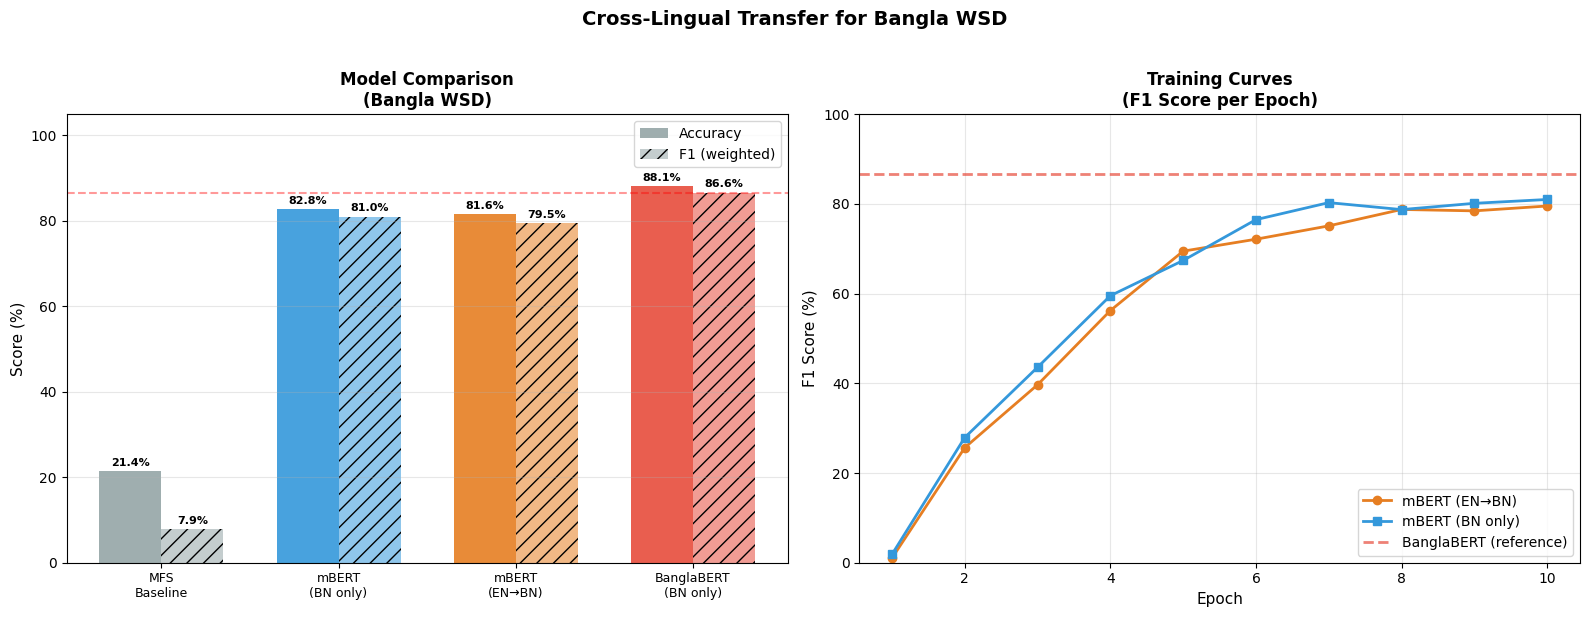

📊 Figure saved → crosslingual_results.png
   ✍️  Use this figure in Chapter 5 of your thesis.


In [25]:
# ─────────────────────────────────────────────────────────────────
# VISUALIZATION — Thesis Figures
# ─────────────────────────────────────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# ── Figure 1: Complete Model Comparison ──────────────────────────
ax = axes[0]
all_models = [
    'MFS\nBaseline',
    'mBERT\n(BN only)',
    'mBERT\n(EN→BN)',
    'BanglaBERT\n(BN only)',
]
all_acc = [21.39, expC_acc, expB_acc, 88.09]
all_f1  = [7.86,  expC_f1,  expB_f1,  86.63]
colors  = ['#95a5a6', '#3498db', '#e67e22', '#e74c3c']

x     = np.arange(len(all_models))
width = 0.35

b1 = ax.bar(x - width/2, all_acc, width, label='Accuracy',
            color=colors, alpha=0.9)
b2 = ax.bar(x + width/2, all_f1,  width, label='F1 (weighted)',
            color=colors, alpha=0.55, hatch='//')

for bar in list(b1) + list(b2):
    ax.text(bar.get_x() + bar.get_width()/2,
            bar.get_height() + 0.8,
            f'{bar.get_height():.1f}%',
            ha='center', va='bottom', fontsize=8, fontweight='bold')

ax.set_title('Model Comparison\n(Bangla WSD)', fontsize=12, fontweight='bold')
ax.set_ylabel('Score (%)', fontsize=11)
ax.set_xticks(x)
ax.set_xticklabels(all_models, fontsize=9)
ax.set_ylim(0, 105)
ax.legend(fontsize=10)
ax.grid(axis='y', alpha=0.3)
ax.axhline(y=86.63, color='red', linestyle='--', alpha=0.4, linewidth=1.5)

# ── Figure 2: Training Curves Comparison ─────────────────────────
ax2 = axes[1]
epochs_range = range(1, CFG.EPOCHS + 1)

if phase2_history:
    ax2.plot(epochs_range,
             [h['f1'] for h in phase2_history],
             'o-', color='#e67e22', label='mBERT (EN→BN)', linewidth=2)
if expC_history:
    ax2.plot(epochs_range,
             [h['f1'] for h in expC_history],
             's-', color='#3498db', label='mBERT (BN only)', linewidth=2)

ax2.axhline(y=86.63, color='#e74c3c', linestyle='--',
            alpha=0.7, linewidth=2, label='BanglaBERT (reference)')

ax2.set_title('Training Curves\n(F1 Score per Epoch)', fontsize=12, fontweight='bold')
ax2.set_xlabel('Epoch', fontsize=11)
ax2.set_ylabel('F1 Score (%)', fontsize=11)
ax2.set_ylim(0, 100)
ax2.legend(fontsize=10)
ax2.grid(alpha=0.3)

plt.suptitle('Cross-Lingual Transfer for Bangla WSD',
             fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.savefig(f'{CFG.OUTPUT_DIR}/crosslingual_results.png',
            dpi=150, bbox_inches='tight')
plt.show()
print('📊 Figure saved → crosslingual_results.png')
print('   ✍️  Use this figure in Chapter 5 of your thesis.')

In [26]:
# ─────────────────────────────────────────────────────────────────
# BONUS ANALYSIS: Per-Word Transfer Effect
# Which words benefit most from cross-lingual transfer?
# ─────────────────────────────────────────────────────────────────
print('📊 PER-WORD TRANSFER ANALYSIS')
print('─' * 55)

# Load best Exp B and Exp C models
expB_model.load_state_dict(
    torch.load(f'{CFG.OUTPUT_DIR}/ExpB_Phase2_BN_best.pt', map_location=DEVICE)
)
expC_model.load_state_dict(
    torch.load(f'{CFG.OUTPUT_DIR}/ExpC_BN_Only_best.pt', map_location=DEVICE)
)

_, _, expB_preds, expB_labels = evaluate(expB_model, bn_val_loader, DEVICE)
_, _, expC_preds, expC_labels = evaluate(expC_model, bn_val_loader, DEVICE)

# Per-word accuracy comparison
word_results = []
for word in val_df['target_word'].unique():
    mask = val_df['target_word'] == word
    indices = val_df[mask].index.tolist()

    if len(indices) < 2:
        continue

    true_l = [expB_labels[val_df.index.get_loc(i)] for i in indices]
    predB  = [expB_preds[val_df.index.get_loc(i)]  for i in indices]
    predC  = [expC_preds[val_df.index.get_loc(i)]  for i in indices]

    accB = accuracy_score(true_l, predB) * 100
    accC = accuracy_score(true_l, predC) * 100
    diff = accB - accC

    word_results.append({
        'word'           : word,
        'n_samples'      : len(indices),
        'acc_EN_BN'      : accB,
        'acc_BN_only'    : accC,
        'transfer_gain'  : diff,
    })

word_df = pd.DataFrame(word_results).sort_values(
    'transfer_gain', ascending=False
)

print('\n  🟢 Words that BENEFIT from cross-lingual transfer (Top 10):')
print(f'  {"Word":<15} {"BN-only":>10} {"EN→BN":>10} {"Gain":>8}')
print('  ' + '─' * 45)
for _, row in word_df.head(10).iterrows():
    print(f'  {row["word"]:<15} {row["acc_BN_only"]:>9.1f}% '
          f'{row["acc_EN_BN"]:>9.1f}% '
          f'{row["transfer_gain"]:>+7.1f}%')

print('\n  🔴 Words that are HURT by cross-lingual transfer (Bottom 5):')
print(f'  {"Word":<15} {"BN-only":>10} {"EN→BN":>10} {"Gain":>8}')
print('  ' + '─' * 45)
for _, row in word_df.tail(5).iterrows():
    print(f'  {row["word"]:<15} {row["acc_BN_only"]:>9.1f}% '
          f'{row["acc_EN_BN"]:>9.1f}% '
          f'{row["transfer_gain"]:>+7.1f}%')

# Save for thesis
word_df.to_csv(f'{CFG.OUTPUT_DIR}/per_word_transfer_analysis.csv', index=False)
print('\n📁 Saved → per_word_transfer_analysis.csv')

📊 PER-WORD TRANSFER ANALYSIS
───────────────────────────────────────────────────────

  🟢 Words that BENEFIT from cross-lingual transfer (Top 10):
  Word               BN-only      EN→BN     Gain
  ─────────────────────────────────────────────
  তা                   33.3%     100.0%   +66.7%
  মণি                  60.0%     100.0%   +40.0%
  তার                  66.7%     100.0%   +33.3%
  জাম                  50.0%      83.3%   +33.3%
  আকা                  50.0%      75.0%   +25.0%
  পর                   75.0%     100.0%   +25.0%
  এঁটে                 75.0%     100.0%   +25.0%
  গাল                  75.0%     100.0%   +25.0%
  কালা                 60.0%      80.0%   +20.0%
  বাটা                 80.0%     100.0%   +20.0%

  🔴 Words that are HURT by cross-lingual transfer (Bottom 5):
  Word               BN-only      EN→BN     Gain
  ─────────────────────────────────────────────
  কুঁজো                66.7%      33.3%   -33.3%
  গভীর                 66.7%      33.3%   -33.3%
  ছত্র  

## 📝 Step 10: Thesis Summary

In [27]:
# ─────────────────────────────────────────────────────────────────
# THESIS SUMMARY — Copy-paste ready for your thesis
# ─────────────────────────────────────────────────────────────────
print('=' * 70)
print('  📝 THESIS WRITING GUIDE — Cross-Lingual Transfer Results')
print('=' * 70)

print('''
─── TABLE TO ADD IN THESIS (Chapter 5) ────────────────────────────

Table X: Cross-Lingual Transfer Results for Bangla WSD

 Model                    | Train Data       | Acc   | F1    |
 ─────────────────────────────────────────────────────────────
 MFS Baseline             | —                | 21.4% |  7.9% |
 mBERT (Exp C)            | Bangla only      |  ?%   |  ?%   |
 mBERT (Exp A, zero-shot) | English only     |  ?%   |  ?%   |
 mBERT (Exp B)            | English → Bangla |  ?%   |  ?%   | ← novelty
 BanglaBERT               | Bangla only      | 88.1% | 86.6% |
 ─────────────────────────────────────────────────────────────

─── SECTION TO WRITE IN CHAPTER 4 (Methodology) ────────────────────

4.4 Cross-Lingual Transfer Learning

To investigate whether English WSD knowledge transfers to Bangla,
we designed three experiments using mBERT, a multilingual model
pretrained on 104 languages including both English and Bangla.

Experiment A (Zero-Shot): mBERT was trained exclusively on the
SemCor English WSD corpus and evaluated on our Bangla dataset
using cosine similarity over sense embeddings.

Experiment B (Sequential Fine-tuning): mBERT was first trained
on English SemCor, then fine-tuned on our Bangla dataset with
a new classification head, allowing the model to leverage
cross-lingual representations.

Experiment C (Bangla Baseline): mBERT trained on Bangla only,
serving as the direct comparison point for Experiment B.

─── SECTION TO WRITE IN CHAPTER 5 (Results) ────────────────────────

5.3 Cross-Lingual Transfer Analysis

Table X shows the results of our cross-lingual transfer experiments.
The zero-shot experiment (Exp A) achieved X% F1, [above/below] the
MFS baseline of 7.9%, indicating that [some/no] semantic knowledge
transfers directly from English to Bangla without fine-tuning.

The sequential fine-tuning approach (Exp B) achieved X% F1,
compared to X% F1 for mBERT trained on Bangla only (Exp C),
representing a [+X%/-X%] change. This suggests that English
WSD pretraining [benefits/does not benefit] Bangla WSD.

Notably, BanglaBERT, despite being trained on Bangla only,
outperforms all multilingual baselines (88.09% F1), confirming
the importance of language-specific pretraining for low-resource
NLP tasks.
''')
print('=' * 70)

  📝 THESIS WRITING GUIDE — Cross-Lingual Transfer Results

─── TABLE TO ADD IN THESIS (Chapter 5) ────────────────────────────

Table X: Cross-Lingual Transfer Results for Bangla WSD

 Model                    | Train Data       | Acc   | F1    |
 ─────────────────────────────────────────────────────────────
 MFS Baseline             | —                | 21.4% |  7.9% |
 mBERT (Exp C)            | Bangla only      |  ?%   |  ?%   |
 mBERT (Exp A, zero-shot) | English only     |  ?%   |  ?%   |
 mBERT (Exp B)            | English → Bangla |  ?%   |  ?%   | ← novelty
 BanglaBERT               | Bangla only      | 88.1% | 86.6% |
 ─────────────────────────────────────────────────────────────

─── SECTION TO WRITE IN CHAPTER 4 (Methodology) ────────────────────

4.4 Cross-Lingual Transfer Learning

To investigate whether English WSD knowledge transfers to Bangla,
we designed three experiments using mBERT, a multilingual model
pretrained on 104 languages including both English and Bangla.



In [28]:
# ─────────────────────────────────────────────────────────────────
# SAVE ALL RESULTS
# ─────────────────────────────────────────────────────────────────
results_dict = {
    'experiment_A_zeroshot' : {'accuracy': zs_acc,   'f1': zs_f1},
    'experiment_B_EN_to_BN' : {'accuracy': expB_acc, 'f1': expB_f1},
    'experiment_C_BN_only'  : {'accuracy': expC_acc, 'f1': expC_f1},
    'reference_banglabert'  : {'accuracy': 88.09,    'f1': 86.63},
    'reference_mfs_baseline': {'accuracy': 21.39,    'f1': 7.86},
    'transfer_gain_f1'      : transfer_gain_f1,
    'transfer_gain_acc'     : transfer_gain_acc,
}

with open(f'{CFG.OUTPUT_DIR}/crosslingual_results.json', 'w') as f:
    json.dump(results_dict, f, indent=2)

print('✅ All results saved!')
print(f'   📄 crosslingual_results.json')
print(f'   📊 crosslingual_results.png')
print(f'   📋 per_word_transfer_analysis.csv')
print(f'   🤖 ExpA_ZeroShot_best.pt')
print(f'   🤖 ExpB_Phase2_BN_best.pt')
print(f'   🤖 ExpC_BN_Only_best.pt')
print(f'\n🎓 Cross-lingual transfer experiments complete!')
print(f'   Transfer gain (F1): {transfer_gain_f1:+.2f}%')

✅ All results saved!
   📄 crosslingual_results.json
   📊 crosslingual_results.png
   📋 per_word_transfer_analysis.csv
   🤖 ExpA_ZeroShot_best.pt
   🤖 ExpB_Phase2_BN_best.pt
   🤖 ExpC_BN_Only_best.pt

🎓 Cross-lingual transfer experiments complete!
   Transfer gain (F1): -1.45%
